# Osteocyte segmentation: statistical analysis

Statistics on the pooled pipeline results in `../data/aggregate/` (regenerated by `scripts/import_series.py`
whenever a series is imported, so re-running this notebook picks up every change).

**Data hierarchy.** Cells are nested in series (confocal stacks), series in samples. Cells from one stack share
staining, imaging and segmentation conditions, so they are *not* independent replicates: pooling them as if they
were overstates the evidence (pseudoreplication; Lazic, *BMC Neurosci.* 11:5, 2010,
[doi:10.1186/1471-2202-11-5](https://doi.org/10.1186/1471-2202-11-5)). The analyses below therefore

- describe each series separately,
- quantify how much of the variance lies *between* series (intraclass correlation from a random-intercept model),
- estimate correlations *within* series and give confidence intervals from a cluster bootstrap (resampling series, then cells),
- model dendrite counts with series as a fixed effect.

`SAMPLE_OF` below maps series to samples (digit before the dot: `sample 1.3` → sample 1). Edit it if that is not the
biological grouping. With 4 samples, two of them imaged in a single stack, sample-level comparisons are descriptive only.

Outputs: tables in `results/`, figures in `figures/`.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

HERE = Path.cwd() if Path.cwd().name == "local-analysis" else Path.cwd() / "local-analysis"
DATA = HERE.parent / "data" / "aggregate"
RESULTS, FIGURES = HERE / "results", HERE / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

SEED = 20261014
rng = np.random.default_rng(SEED)
N_BOOT = 2000

# validated categorical slots and neutral inks (light surface)
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781", context="#c3c2b7", grid="#e1e0d9")
DIVERGING = LinearSegmentedColormap.from_list("rb", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9,
    "axes.edgecolor": INK["context"], "axes.labelcolor": INK["secondary"], "axes.titlesize": 10,
    "axes.titleweight": "semibold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": INK["grid"], "grid.linewidth": 0.6,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Data

In [2]:
cells = pd.read_csv(DATA / "osteocytes.csv")
dendrites = pd.read_csv(DATA / "dendrites.csv")
series = pd.read_csv(DATA / "series.csv")


def SAMPLE_OF(name):
    m = re.search(r"(\d+)\.\d+", name)
    return f"sample {m.group(1)}" if m else name


def order_key(name):
    m = re.search(r"(\d+)\.(\d+)", name)
    return (int(m.group(1)), int(m.group(2))) if m else (np.inf, np.inf)


ORDER = sorted(series["series"], key=order_key)
for df in (cells, dendrites, series):
    df["sample"] = df["series"].map(SAMPLE_OF)
    df["series"] = pd.Categorical(df["series"], ORDER, ordered=True)

# quantities analysed per osteocyte: column -> (label, analyse on log scale)
VARS = {
    "volume_um3": ("Volume (µm³)", True),
    "surface_area_um2": ("Surface area (µm²)", True),
    "axis_1_um": ("Longest axis (µm)", False),
    "axis_ratio_2_1": ("Axis ratio 2:1", False),
    "flatness": ("Flatness", False),
    "Solidity": ("Solidity", False),
    "nucleus_volume_um3": ("Nucleus volume (µm³)", False),
    "n_dendrites": ("Dendrites per cell", False),
    "mean_dendrite_reach_um": ("Mean dendrite reach (µm)", False),
    "max_dendrite_reach_um": ("Max dendrite reach (µm)", False),
}

# dendrites whose skeleton is far longer than their reach are dense meshes next to the cell, not processes
# (e.g. 674 µm of skeleton and 104 tips within 12 µm of the body); flagged and excluded from path/tip statistics
dendrites["path_per_reach"] = dendrites["path_um"] / dendrites["reach_um"]
dendrites["bushy"] = dendrites["n_tips"] > 20

print(f"{len(cells)} osteocytes, {len(dendrites)} dendrites, {len(series)} series, {series['sample'].nunique()} samples")
series[["sample", "series", "osteocytes", "dendrites", "nuclei_in_hull"]].sort_values("series")

196 osteocytes, 1340 dendrites, 8 series, 4 samples


,sample,series,osteocytes,dendrites,nuclei_in_hull
0,sample 1,sample 1.1,41,263,91
7,sample 1,smple 1.2,15,146,42
1,sample 1,sample 1.3,16,117,31
2,sample 1,sample 1.4,40,336,80
3,sample 2,sample 2.1_ultrasonic cleaned,21,151,35
4,sample 3,sample 3.1,23,133,43
5,sample 3,sample 3.2,27,131,57
6,sample 4,sample 4.1,13,63,23


## Quality control

Series with few cells contribute noisy estimates; they are kept but flagged. `bushy` counts the dendrites flagged above.

In [3]:
MIN_CELLS = 10
qc = (cells.groupby("series", observed=True).size().rename("cells").to_frame()
      .join(dendrites.groupby("series", observed=True).agg(dendrites=("label", "size"), bushy=("bushy", "sum"))))
qc["sample"] = [SAMPLE_OF(s) for s in qc.index]
qc["few cells"] = qc["cells"] < MIN_CELLS
qc.to_csv(RESULTS / "qc.csv")
qc

,cells,dendrites,bushy,sample,few cells
series,,,,,
sample 1.1,41,263,0,sample 1,False
smple 1.2,15,146,0,sample 1,False
sample 1.3,16,117,0,sample 1,False
sample 1.4,40,336,1,sample 1,False
sample 2.1_ultrasonic cleaned,21,151,2,sample 2,False
sample 3.1,23,133,4,sample 3,False
sample 3.2,27,131,1,sample 3,False
sample 4.1,13,63,0,sample 4,False


## Descriptive statistics

Median [interquartile range] per series. Medians and quartiles because most quantities are skewed.

In [4]:
def describe(df, by):
    rows = []
    for key, g in df.groupby(by, observed=True):
        for col, (label, _) in VARS.items():
            v = g[col].dropna()
            rows.append({by: key, "quantity": label, "n": len(v), "median": v.median(),
                         "q1": v.quantile(0.25), "q3": v.quantile(0.75), "mean": v.mean(), "sd": v.std()})
    return pd.DataFrame(rows)


desc_series = describe(cells, "series")
desc_sample = describe(cells, "sample")
desc_series.to_csv(RESULTS / "descriptives_by_series.csv", index=False)
desc_sample.to_csv(RESULTS / "descriptives_by_sample.csv", index=False)

fmt = lambda r: f"{r['median']:.3g} [{r['q1']:.3g}, {r['q3']:.3g}]"
desc_series.assign(value=desc_series.apply(fmt, axis=1)).pivot(index="quantity", columns="series", values="value") \
    .loc[[label for label, _ in VARS.values()], ORDER]

series,sample 1.1,smple 1.2,sample 1.3,sample 1.4,sample 2.1_ultrasonic cleaned,sample 3.1,sample 3.2,sample 4.1
quantity,,,,,,,,
Volume (µm³),"1.5e+03 [1.06e+03, 2.16e+03]","1.2e+03 [1.12e+03, 2.06e+03]","774 [383, 1.32e+03]","1.37e+03 [427, 2.02e+03]","862 [645, 1.28e+03]","525 [357, 613]","358 [280, 448]","761 [493, 878]"
Surface area (µm²),"1.77e+03 [1.33e+03, 2.26e+03]","1.77e+03 [1.48e+03, 2.53e+03]","1.2e+03 [619, 2.41e+03]","1.71e+03 [583, 2.8e+03]","1.44e+03 [927, 1.9e+03]","1.02e+03 [674, 1.32e+03]","609 [476, 937]","850 [695, 1.36e+03]"
Longest axis (µm),"33.2 [25.5, 39.8]","37.2 [32.7, 45.1]","29.8 [24.1, 42.3]","36.3 [27.2, 45.2]","39.2 [35.7, 41.7]","36.1 [26.5, 40.7]","28.8 [25, 34.8]","26.6 [20, 31.6]"
Axis ratio 2:1,"0.465 [0.355, 0.597]","0.404 [0.319, 0.51]","0.468 [0.406, 0.532]","0.373 [0.294, 0.54]","0.321 [0.26, 0.383]","0.371 [0.267, 0.483]","0.282 [0.219, 0.345]","0.51 [0.473, 0.616]"
Flatness,"0.601 [0.558, 0.721]","0.61 [0.471, 0.745]","0.583 [0.449, 0.709]","0.583 [0.493, 0.676]","0.667 [0.558, 0.751]","0.547 [0.372, 0.672]","0.714 [0.548, 0.799]","0.649 [0.484, 0.692]"
Solidity,"0.411 [0.335, 0.458]","0.306 [0.223, 0.385]","0.3 [0.194, 0.384]","0.336 [0.265, 0.446]","0.321 [0.288, 0.376]","0.246 [0.191, 0.318]","0.361 [0.23, 0.453]","0.435 [0.31, 0.549]"
Nucleus volume (µm³),"40.1 [33.5, 57]","45.8 [42.2, 49.2]","47.7 [42.4, 64.7]","43.8 [38.6, 52.7]","33.3 [26.9, 36.8]","62.4 [54.9, 67.6]","33.6 [30.2, 41.7]","82.4 [41.5, 106]"
Dendrites per cell,"5 [4, 9]","8 [5.5, 13]","5 [3, 11.2]","9 [4, 11]","7 [6, 9]","6 [3.5, 7.5]","4 [3, 6]","5 [1, 7]"
Mean dendrite reach (µm),"3.65 [2.75, 5.51]","4.26 [3.33, 5.89]","5 [3.75, 7.96]","3.92 [3.14, 6]","5.87 [4.94, 7.78]","6.51 [5.6, 7.64]","4.98 [3.76, 6.45]","4.63 [4.16, 6.11]"


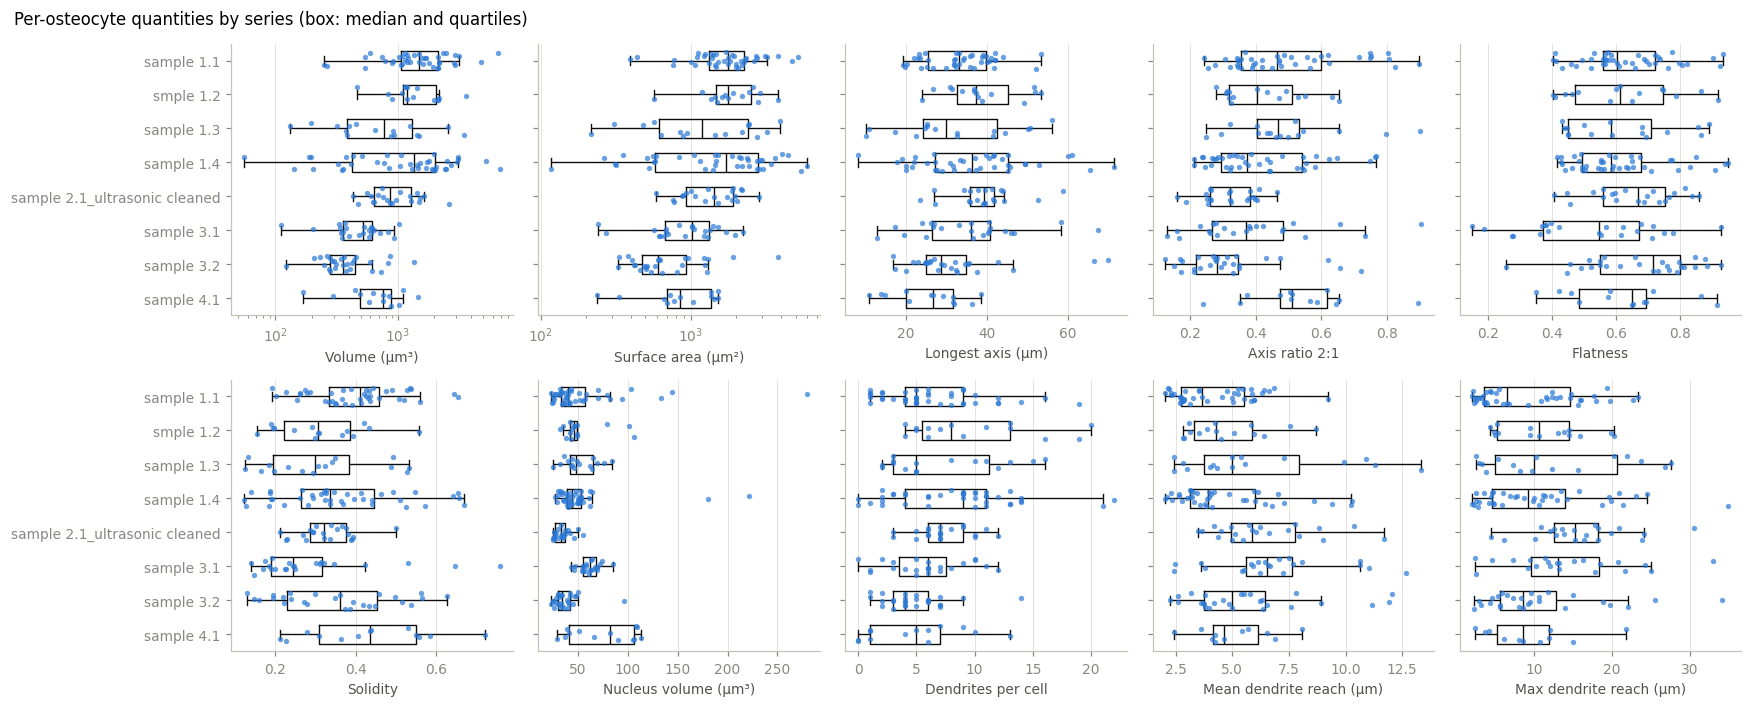

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharey=True)
for ax, (col, (label, log)) in zip(axes.flat, VARS.items()):
    d = cells.dropna(subset=[col])
    if log:
        d = d[d[col] > 0]
    sns.stripplot(d, x=col, y="series", order=ORDER, ax=ax, color=SLOT[0], size=3.5, alpha=0.7, jitter=0.25)
    sns.boxplot(d, x=col, y="series", order=ORDER, ax=ax, showfliers=False, width=0.55, fill=False,
                color=INK["primary"], linewidth=0.9)
    ax.set(xlabel=label, ylabel="", xscale="log" if log else "linear")
fig.suptitle("Per-osteocyte quantities by series (box: median and quartiles)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "distributions_by_series.png")

## Dye penetration: nucleus census

For every series, the cleaned ch0 nuclei inside the hull on the bone side and not in soft tissue, split into: inside a
surviving osteocyte, inside a ch1 region the filters rejected, and without ch1 signal (the dye did not reach the cell).
Proportions with Wilson 95% intervals; a χ² test of homogeneity asks whether the split differs between series.

χ² homogeneity across series: χ²(14) = 19.5, p = 0.15; 2 of 24 expected counts < 5
pooled fractions: In an osteocyte 55%, In a rejected ch1 region 22%, No ch1 signal 23%


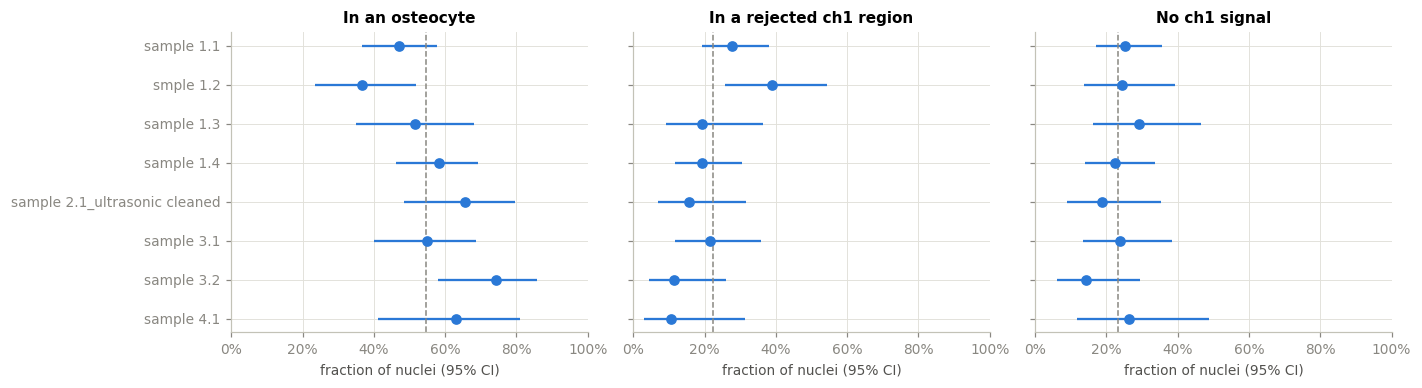

In [6]:
census = series.sort_values("series").copy()
census["nuclei"] = census["detected"] + census["labelled_rejected"] + census["no_ch1"]
CLASSES = {"detected": "In an osteocyte", "labelled_rejected": "In a rejected ch1 region", "no_ch1": "No ch1 signal"}
rows = []
for _, r in census.iterrows():
    for key, label in CLASSES.items():
        lo, hi = proportion_confint(r[key], r["nuclei"], method="wilson")
        rows.append(dict(series=r["series"], sample=r["sample"], outcome=label, k=r[key], n=r["nuclei"],
                         fraction=r[key] / r["nuclei"], ci_low=lo, ci_high=hi))
census_ci = pd.DataFrame(rows)
census_ci.to_csv(RESULTS / "nucleus_census_ci.csv", index=False)

table = census[list(CLASSES)].to_numpy()
chi2, p_census, dof, expected = stats.chi2_contingency(table)
print(f"χ² homogeneity across series: χ²({dof}) = {chi2:.1f}, p = {p_census:.2g}; "
      f"{(expected < 5).sum()} of {expected.size} expected counts < 5")
pooled = census[list(CLASSES)].sum() / census["nuclei"].sum()
print("pooled fractions:", ", ".join(f"{CLASSES[k]} {v:.0%}" for k, v in pooled.items()))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (key, label) in zip(axes, CLASSES.items()):
    d = census_ci[census_ci["outcome"] == label].set_index("series").loc[ORDER]
    y = np.arange(len(d))
    ax.errorbar(d["fraction"], y, xerr=[d["fraction"] - d["ci_low"], d["ci_high"] - d["fraction"]],
                fmt="o", color=SLOT[0], ecolor=SLOT[0], elinewidth=1.5, capsize=0, markersize=6)
    ax.axvline(pooled[key], color=INK["muted"], linewidth=1, linestyle="--")
    ax.set(title=label, xlim=(0, 1), yticks=y, yticklabels=d.index, xlabel="fraction of nuclei (95% CI)")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIGURES / "nucleus_census.png")

## How much do series differ?

For each quantity (log10 where skewed):

- **ICC**: share of the variance that lies between series, from a random-intercept model
  $y_{ij} = \mu + u_i + \varepsilon_{ij}$, $\mathrm{ICC} = \sigma_u^2 / (\sigma_u^2 + \sigma_\varepsilon^2)$.
  An ICC near 0 means stacks look alike and cells could almost be pooled; a large ICC means the stack (biology,
  staining or segmentation) matters and must be accounted for.
- **Kruskal–Wallis** test across series, with effect size $\varepsilon^2 = (H - k + 1)/(n - k)$ and Holm-adjusted p-values.

These compare *stacks*, not biological conditions: a difference can come from imaging or segmentation quality as much
as from the bone.

In [7]:
def icc(df, col):
    d = df[["series", col]].dropna().rename(columns={col: "y"})
    d["series"] = d["series"].astype(str)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = smf.mixedlm("y ~ 1", d, groups=d["series"]).fit(reml=True)
    between = float(fit.cov_re.iloc[0, 0])
    return between / (between + fit.scale)


rows = []
for col, (label, log) in VARS.items():
    d = cells.dropna(subset=[col])
    if log:
        d = d[d[col] > 0].assign(**{col: np.log10(d.loc[d[col] > 0, col])})
    groups = [g[col].to_numpy() for _, g in d.groupby("series", observed=True) if len(g) >= 2]
    h, p = stats.kruskal(*groups)
    n, k = sum(map(len, groups)), len(groups)
    rows.append(dict(quantity=label, scale="log10" if log else "linear", n=n, series=k,
                     ICC=icc(d, col), H=h, p=p, epsilon2=(h - k + 1) / (n - k)))
series_effects = pd.DataFrame(rows)
series_effects["p_holm"] = multipletests(series_effects["p"], method="holm")[1]
series_effects.to_csv(RESULTS / "series_effects.csv", index=False)
series_effects.round(3)

,quantity,scale,n,series,ICC,H,p,epsilon2,p_holm
0,Volume (µm³),log10,196,8,0.286,67.928,0.000,0.324,0.000
1,Surface area (µm²),log10,196,8,0.184,44.520,0.000,0.200,0.000
2,Longest axis (µm),linear,196,8,0.063,20.556,0.004,0.072,0.022
3,Axis ratio 2:1,linear,196,8,0.176,40.445,0.000,0.178,0.000
4,Flatness,linear,196,8,0.050,12.171,0.095,0.028,0.095
5,Solidity,linear,196,8,0.062,20.587,0.004,0.072,0.022
6,Nucleus volume (µm³),linear,196,8,0.108,57.879,0.000,0.271,0.000
7,Dendrites per cell,linear,196,8,0.096,19.782,0.006,0.068,0.022
8,Mean dendrite reach (µm),linear,191,8,0.108,26.723,0.000,0.108,0.002
9,Max dendrite reach (µm),linear,191,8,0.062,19.216,0.008,0.067,0.022


### Series and samples

Series medians grouped by sample, over each series' interquartile range. With four samples, two imaged in a single
stack, this is a description of the spread, not a test.

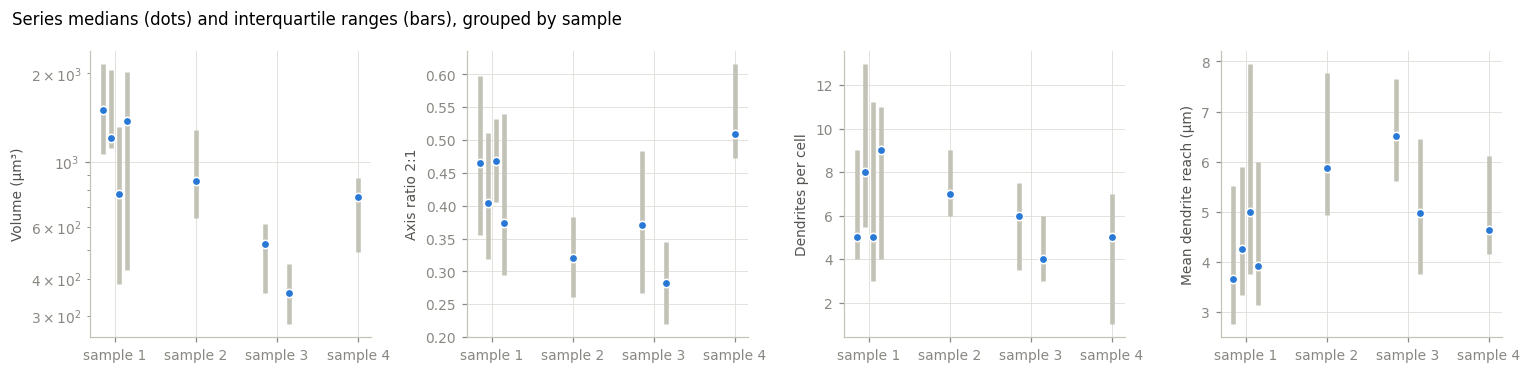

In [8]:
show = ["volume_um3", "axis_ratio_2_1", "n_dendrites", "mean_dendrite_reach_um"]
samples = sorted(series["sample"].unique(), key=lambda s: order_key(s + ".0"))
fig, axes = plt.subplots(1, len(show), figsize=(14, 3.4))
for ax, col in zip(axes, show):
    label, log = VARS[col]
    d = desc_series[desc_series["quantity"] == label].copy()
    d["sample"] = d["series"].map(SAMPLE_OF)
    for i, s in enumerate(samples):
        g = d[d["sample"] == s]
        x = i + np.linspace(-0.15, 0.15, len(g)) if len(g) > 1 else np.array([i])
        ax.vlines(x, g["q1"], g["q3"], color=INK["context"], linewidth=3)
        ax.scatter(x, g["median"], color=SLOT[0], s=30, zorder=3, edgecolor="white", linewidth=1)
    ax.set(xticks=range(len(samples)), xticklabels=samples, ylabel=label, yscale="log" if log else "linear")
fig.suptitle("Series medians (dots) and interquartile ranges (bars), grouped by sample", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "series_by_sample.png")

## Correlations between quantities

Spearman correlations, two ways:

- **pooled**: all cells together, which mixes within-series association with differences between series;
- **within series**: ranks taken inside each series (as fractions, so series of different size weigh alike) and then
  correlated, which removes shifts between series. When the two disagree, differences between stacks are driving the
  pooled value.

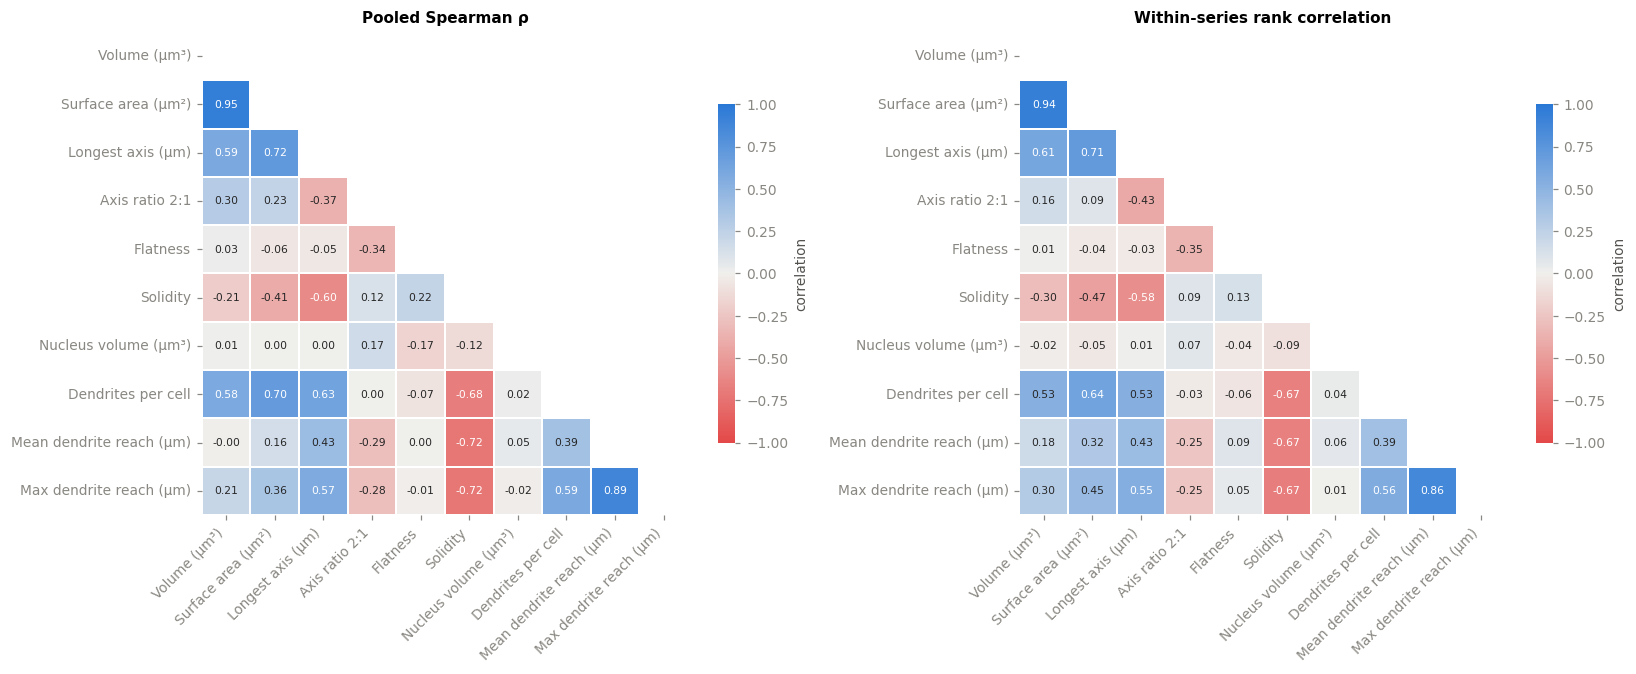

In [9]:
cols = list(VARS)
labels = [VARS[c][0] for c in cols]
pooled_r = cells[cols].corr(method="spearman")
within_r = cells.groupby("series", observed=True)[cols].rank(pct=True).corr(method="pearson")
pooled_r.set_axis(labels, axis=0).set_axis(labels, axis=1).to_csv(RESULTS / "correlations_pooled.csv")
within_r.set_axis(labels, axis=0).set_axis(labels, axis=1).to_csv(RESULTS / "correlations_within_series.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
mask = np.triu(np.ones_like(pooled_r, dtype=bool))
for ax, r, title in [(axes[0], pooled_r, "Pooled Spearman ρ"), (axes[1], within_r, "Within-series rank correlation")]:
    sns.heatmap(r, mask=mask, ax=ax, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws=dict(size=7), xticklabels=labels, yticklabels=labels, linewidths=1, linecolor="white",
                cbar_kws=dict(shrink=0.7, label="correlation"))
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(FIGURES / "correlations.png")

### Cluster-bootstrap intervals for selected pairs

Confidence intervals that respect the nesting: each replicate resamples series with replacement, then cells within
each drawn series (Field & Welsh, *J. R. Stat. Soc. B* 69:369, 2007,
[doi:10.1111/j.1467-9868.2007.00593.x](https://doi.org/10.1111/j.1467-9868.2007.00593.x)). With only
eight series the intervals are wide, and honestly so.

In [10]:
PAIRS = [("volume_um3", "n_dendrites"), ("volume_um3", "mean_dendrite_reach_um"),
         ("nucleus_volume_um3", "volume_um3"), ("axis_ratio_2_1", "n_dendrites"),
         ("flatness", "mean_dendrite_reach_um")]


def cluster_bootstrap_spearman(df, a, b, n_boot=N_BOOT):
    groups = [g[[a, b]].dropna().to_numpy() for _, g in df.groupby("series", observed=True)]
    groups = [g for g in groups if len(g)]
    estimate = stats.spearmanr(*np.concatenate(groups).T).statistic
    boot = np.empty(n_boot)
    for i in range(n_boot):
        drawn = [groups[j] for j in rng.integers(0, len(groups), len(groups))]
        x = np.concatenate([g[rng.integers(0, len(g), len(g))] for g in drawn])
        boot[i] = stats.spearmanr(x[:, 0], x[:, 1]).statistic
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return estimate, lo, hi


rows = []
for a, b in PAIRS:
    est, lo, hi = cluster_bootstrap_spearman(cells, a, b)
    rows.append(dict(x=VARS[a][0], y=VARS[b][0], spearman=est, ci_low=lo, ci_high=hi,
                     within_series=within_r.loc[a, b]))
boot_table = pd.DataFrame(rows)
boot_table.to_csv(RESULTS / "correlations_cluster_bootstrap.csv", index=False)
boot_table.round(3)

,x,y,spearman,ci_low,ci_high,within_series
0,Volume (µm³),Dendrites per cell,0.583,0.287,0.806,0.530
1,Volume (µm³),Mean dendrite reach (µm),-0.002,-0.257,0.347,0.177
2,Nucleus volume (µm³),Volume (µm³),0.014,-0.294,0.275,-0.018
3,Axis ratio 2:1,Dendrites per cell,0.001,-0.210,0.196,-0.026
4,Flatness,Mean dendrite reach (µm),0.003,-0.197,0.232,0.088


## Dendrite count and cell size

Do larger osteocytes carry more dendrites? Quasi-Poisson regression of dendrites per cell on $\log_2$ volume, with
series as a fixed effect, so the slope is estimated within series. Quasi-Poisson keeps the Poisson mean model but
scales the standard errors by the measured dispersion (Pearson χ²/df), so overdispersed counts do not give
overconfident intervals. The coefficient is reported as a rate ratio: the multiplicative change in expected dendrite
count per doubling of cell volume.

quasi-Poisson (dispersion 1.50): rate ratio per doubling of volume = 1.47 (95% CI 1.37–1.57), p = 3e-27


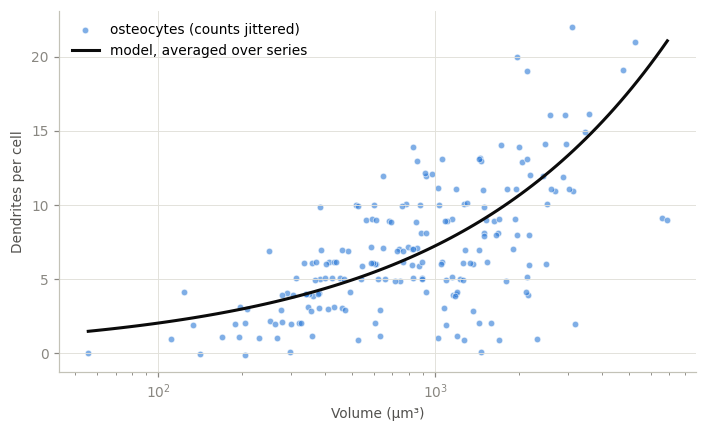

In [11]:
d = cells[cells["volume_um3"] > 0].copy()
d["log2_volume"] = np.log2(d["volume_um3"])
d["series_name"] = d["series"].astype(str)
formula = "n_dendrites ~ log2_volume + C(series_name)"

model = smf.glm(formula, d, family=sm.families.Poisson()).fit(scale="X2")
name = f"quasi-Poisson (dispersion {model.scale:.2f})"
beta, (beta_lo, beta_hi) = model.params["log2_volume"], model.conf_int().loc["log2_volume"]
print(f"{name}: rate ratio per doubling of volume = {np.exp(beta):.2f} "
      f"(95% CI {np.exp(beta_lo):.2f}–{np.exp(beta_hi):.2f}), p = {model.pvalues['log2_volume']:.2g}")
(RESULTS / "dendrite_count_model.txt").write_text(f"{name}\n\n{model.summary()}\n")

# fitted curve averaged over series
grid = np.linspace(d["log2_volume"].min(), d["log2_volume"].max(), 100)
fitted = np.mean([model.predict(pd.DataFrame({"log2_volume": grid, "series_name": s}))
                  for s in d["series_name"].unique()], axis=0)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(d["volume_um3"], d["n_dendrites"] + rng.uniform(-0.15, 0.15, len(d)), s=18, color=SLOT[0], alpha=0.6,
           edgecolor="white", linewidth=0.6, label="osteocytes (counts jittered)")
ax.plot(2 ** grid, fitted, color=INK["primary"], linewidth=2, label="model, averaged over series")
ax.set(xscale="log", xlabel="Volume (µm³)", ylabel="Dendrites per cell")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "dendrites_vs_volume.png")

## Dendrite reach

Empirical cumulative distribution of dendrite reach (distance from the cell body surface) in each series, against all
series pooled (grey). Reach is the robust length measure; skeleton path length is unreliable for short, thick processes
and inflated by the bushy artefacts.

excluded 8 bushy dendrites; reach median 3.76 µm, 90th percentile 12.01 µm


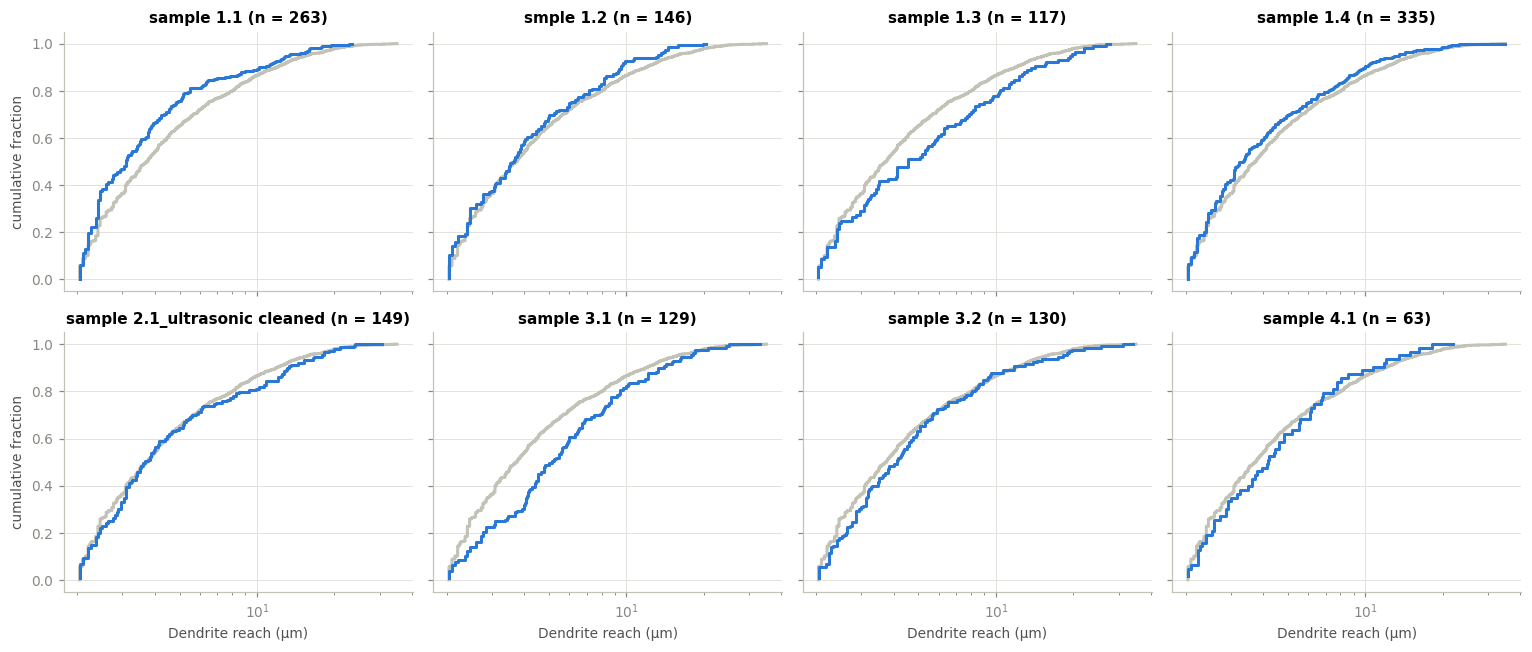

In [12]:
ok = dendrites[~dendrites["bushy"]]
pooled_reach = np.sort(ok["reach_um"].to_numpy())
n = len(ORDER)
ncols = 4
fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(14, 3 * np.ceil(n / ncols)), sharex=True, sharey=True)
for ax, s in zip(axes.flat, ORDER):
    v = np.sort(ok.loc[ok["series"] == s, "reach_um"].to_numpy())
    ax.step(pooled_reach, np.arange(1, len(pooled_reach) + 1) / len(pooled_reach), color=INK["context"], linewidth=2)
    ax.step(v, np.arange(1, len(v) + 1) / len(v), color=SLOT[0], linewidth=2)
    ax.set(title=f"{s} (n = {len(v)})", xscale="log")
for ax in axes.flat[n:]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Dendrite reach (µm)")
for ax in axes[:, 0]:
    ax.set_ylabel("cumulative fraction")
fig.tight_layout()
fig.savefig(FIGURES / "dendrite_reach_ecdf.png")

print(f"excluded {dendrites['bushy'].sum()} bushy dendrites; reach median {ok['reach_um'].median():.2f} µm, "
      f"90th percentile {ok['reach_um'].quantile(0.9):.2f} µm")

## Summary

In [13]:
print(f"{len(cells)} osteocytes in {len(ORDER)} series from {series['sample'].nunique()} samples\n")
print("Share of variance between series (ICC) and Kruskal–Wallis across series:")
print(series_effects[["quantity", "ICC", "epsilon2", "p_holm"]].round(3).to_string(index=False))
print("\nCluster-bootstrap Spearman correlations (95% CI):")
for _, r in boot_table.iterrows():
    print(f"  {r['x']} vs {r['y']}: {r['spearman']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]")
print(f"\nDendrite count: {name}, rate ratio per doubling of volume {np.exp(beta):.2f} "
      f"[{np.exp(beta_lo):.2f}, {np.exp(beta_hi):.2f}]")
print(f"Nuclei without ch1 signal (pooled): {pooled['no_ch1']:.0%}; χ² homogeneity p = {p_census:.2g}")

196 osteocytes in 8 series from 4 samples

Share of variance between series (ICC) and Kruskal–Wallis across series:
                quantity   ICC  epsilon2  p_holm
            Volume (µm³) 0.286     0.324   0.000
      Surface area (µm²) 0.184     0.200   0.000
       Longest axis (µm) 0.063     0.072   0.022
          Axis ratio 2:1 0.176     0.178   0.000
                Flatness 0.050     0.028   0.095
                Solidity 0.062     0.072   0.022
    Nucleus volume (µm³) 0.108     0.271   0.000
      Dendrites per cell 0.096     0.068   0.022
Mean dendrite reach (µm) 0.108     0.108   0.002
 Max dendrite reach (µm) 0.062     0.067   0.022

Cluster-bootstrap Spearman correlations (95% CI):
  Volume (µm³) vs Dendrites per cell: +0.58 [+0.29, +0.81]
  Volume (µm³) vs Mean dendrite reach (µm): -0.00 [-0.26, +0.35]
  Nucleus volume (µm³) vs Volume (µm³): +0.01 [-0.29, +0.27]
  Axis ratio 2:1 vs Dendrites per cell: +0.00 [-0.21, +0.20]
  Flatness vs Mean dendrite reach (µm): +0.00 [-